In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
!pip install -q chemprop

import numpy as np, pandas as pd, subprocess, glob, torch
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
RDLogger.DisableLog("rdApp.*")
pd.set_option("display.width", 200)
print("GPU available:", torch.cuda.is_available())

clean = pd.read_csv(glob.glob("/kaggle/input/**/my_data_clean.csv", recursive=True)[0])
print(clean.shape)

GPU available: True
(17850, 9)


In [2]:
heavy = {s: Chem.MolFromSmiles(s).GetNumHeavyAtoms() for s in clean.solv.unique()}
is_film = (clean.chrom == clean.solv) | clean.solv.map(lambda s: heavy[s] > 20)   # neat or doped films
sol = clean[~is_film].copy()
sol["abs_eV"] = 1239.84 / sol.abs_nm
print(f"solution-phase pairs: {len(sol)} (removed {is_film.sum()} film rows) | with absorption: {sol.abs_eV.notna().sum()}")

solution-phase pairs: 16694 (removed 1156 film rows) | with absorption: 15390


In [3]:
def group_split(keys, seed):
    """Put whole groups (all rows sharing a key) into train/val/test, 80/10/10 by row count."""
    sizes = keys.value_counts().sample(frac=1, random_state=seed)
    split, count, n = {}, 0, len(keys)
    for g, size in sizes.items():
        split[g] = "train" if count < 0.8 * n else ("val" if count < 0.9 * n else "test")
        count += size
    return keys.map(split)

def make_split(df, kind, seed):
    if kind == "random":     # each molecule-solvent pair independent: easiest test
        r = np.random.default_rng(seed).random(len(df))
        return pd.Series(np.where(r < 0.8, "train", np.where(r < 0.9, "val", "test")), index=df.index)
    if kind == "dye":        # all solvents of one chromophore stay together
        return group_split(df.chrom, seed)
    if kind == "scaffold":   # all chromophores sharing a scaffold stay together: hardest test
        return group_split(df.scaffold, seed)

RUNS = [("abs", "random"), ("abs", "dye"), ("abs", "scaffold"), ("emi", "random")]
SEEDS = [42, 0, 1]
EPOCHS = 60          # my test run was still improving near epoch 40; early stopping ends converged runs anyway
work, out = "/tmp/rep_work", "/kaggle/working/reproduction"
os.makedirs(work, exist_ok=True); os.makedirs(out, exist_ok=True)

def run(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-2000:])
        raise RuntimeError("command failed: " + cmd[:80])

In [4]:
for target, kind in RUNS:
    col = "abs_eV" if target == "abs" else "emi_eV"
    data = sol.dropna(subset=[col])
    for s in SEEDS:
        tag = f"{target}_{kind}_seed{s}"
        if os.path.exists(f"{out}/preds_{tag}.csv"):
            print("already done:", tag); continue
        d = data.assign(split=make_split(data, kind, s))
        d[["chrom", "solv", col, "split"]].to_csv(f"{work}/all.csv", index=False)
        test = d[d.split == "test"]
        test[["chrom", "solv"]].to_csv(f"{work}/test.csv", index=False)
        run(f"rm -rf {work}/m")
        run(f"chemprop train --data-path {work}/all.csv --splits-column split --smiles-columns chrom solv "
            f"--target-columns {col} --task-type regression --epochs {EPOCHS} --patience 10 --batch-size 64 "
            f"--depth 4 --message-hidden-dim 300 --ffn-num-layers 2 --pytorch-seed {s} --save-dir {work}/m")
        run(f"chemprop predict --test-path {work}/test.csv --smiles-columns chrom solv "
            f"--model-paths {work}/m --preds-path {work}/p.csv")
        pred_nm = 1239.84 / pd.read_csv(f"{work}/p.csv")[col].values
        true_nm = test.abs_nm.values if target == "abs" else test.emi_nm.values
        pd.DataFrame({"chrom": test.chrom.values, "solv": test.solv.values,
                      "true_nm": true_nm, "pred_nm": pred_nm}).to_csv(f"{out}/preds_{tag}.csv", index=False)
        print(f"{tag}: test n={len(test)}, MAE {np.abs(pred_nm - true_nm).mean():.1f} nm")

abs_random_seed42: test n=1495, MAE 9.8 nm
abs_random_seed0: test n=1529, MAE 9.6 nm
abs_random_seed1: test n=1560, MAE 9.3 nm
abs_dye_seed42: test n=1539, MAE 16.9 nm
abs_dye_seed0: test n=1539, MAE 17.0 nm
abs_dye_seed1: test n=1535, MAE 18.3 nm
abs_scaffold_seed42: test n=1529, MAE 26.5 nm
abs_scaffold_seed0: test n=1539, MAE 27.3 nm
abs_scaffold_seed1: test n=1539, MAE 21.8 nm
emi_random_seed42: test n=1644, MAE 14.5 nm
emi_random_seed0: test n=1644, MAE 13.8 nm
emi_random_seed1: test n=1689, MAE 14.1 nm


In [5]:
rows = []
for target, kind in RUNS:
    for s in SEEDS:
        p = pd.read_csv(f"{out}/preds_{target}_{kind}_seed{s}.csv")
        e = p.pred_nm - p.true_nm
        rows.append({"target": target, "split": kind, "seed": s, "MAE": e.abs().mean(),
                     "RMSE": np.sqrt((e ** 2).mean()),
                     "R2": 1 - (e ** 2).sum() / ((p.true_nm - p.true_nm.mean()) ** 2).sum()})
res = pd.DataFrame(rows)
res.round(2).to_csv(f"{out}/reproduction_results.csv", index=False)
summ = res.groupby(["target", "split"], sort=False)[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(2)
summ["published"] = ["Greenman 2022: MAE < 10 nm", "Greenman 2022: MAE 13-21 nm",
                     "Greenman 2022: MAE 18-27 nm (best 18.3)", "Joung 2021: RMSE 28.0 nm (split not stated)"]
print(summ.to_string())

                   MAE         RMSE           R2                                          published
                  mean   std   mean    std  mean   std                                             
target split                                                                                       
abs    random     9.57  0.24  15.86   0.42  0.97  0.00                   Greenman 2022: MAE < 10 nm
       dye       17.42  0.80  27.05   0.61  0.92  0.01                  Greenman 2022: MAE 13-21 nm
       scaffold  25.19  2.96  60.39  43.92  0.44  0.71      Greenman 2022: MAE 18-27 nm (best 18.3)
emi    random    14.17  0.36  22.54   0.70  0.94  0.00  Joung 2021: RMSE 28.0 nm (split not stated)


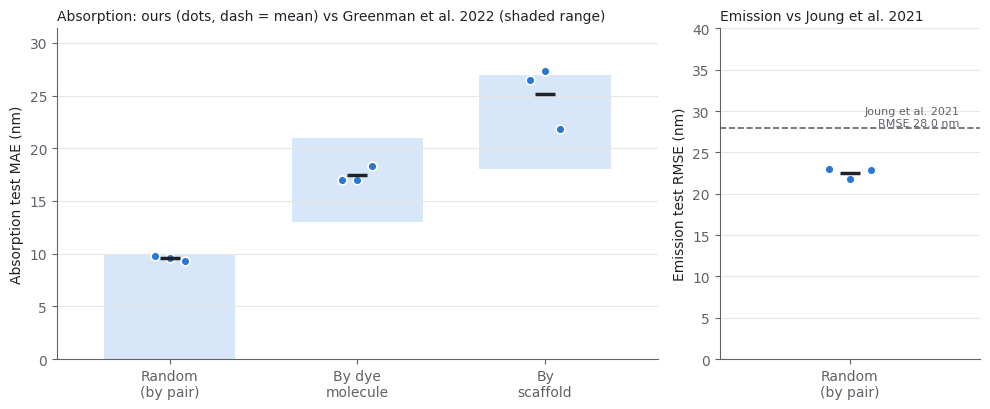

In [6]:
INK, MUTED, GRID, BAND, OURS = "#1f2328", "#5f6368", "#e6e6e3", "#d7e6f8", "#2a78d6"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titlesize": 11, "savefig.dpi": 300, "savefig.bbox": "tight"})
PUB = {"random": (0, 10), "dye": (13, 21), "scaffold": (18, 27)}   # Greenman et al. 2022, absorption MAE on Deep4Chem
LAB = {"random": "Random\n(by pair)", "dye": "By dye\nmolecule", "scaffold": "By\nscaffold"}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [3, 1.3]})
ax = axes[0]
a = res[res.target == "abs"]
for i, kind in enumerate(["random", "dye", "scaffold"]):
    lo, hi = PUB[kind]
    ax.add_patch(plt.Rectangle((i - 0.35, lo), 0.7, hi - lo, color=BAND, zorder=0, lw=0))
    v = a[a.split == kind].MAE
    ax.scatter(np.full(len(v), i) + np.linspace(-0.08, 0.08, len(v)), v, s=40, color=OURS, edgecolor="white", lw=1.2, zorder=3)
    ax.scatter(i, v.mean(), s=200, marker="_", color=INK, lw=2.5, zorder=4)
ax.set_xticks(range(3), [LAB[k] for k in ["random", "dye", "scaffold"]])
ax.set_xlim(-0.6, 2.6); ax.set_ylim(0, max(30, a.MAE.max() * 1.15))
ax.set_ylabel("Absorption test MAE (nm)")
ax.set_title("Absorption: ours (dots, dash = mean) vs Greenman et al. 2022 (shaded range)", fontsize=10)
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)

ax = axes[1]
e = res[(res.target == "emi") & (res.split == "random")]
ax.axhline(28.0, color=MUTED, ls="--", lw=1.2)
ax.text(0.42, 28.0, "Joung et al. 2021\nRMSE 28.0 nm", va="bottom", ha="right", fontsize=8, color=MUTED)
ax.scatter(np.linspace(-0.08, 0.08, len(e)), e.RMSE, s=40, color=OURS, edgecolor="white", lw=1.2, zorder=3)
ax.scatter(0, e.RMSE.mean(), s=200, marker="_", color=INK, lw=2.5, zorder=4)
ax.set_xticks([0], ["Random\n(by pair)"]); ax.set_xlim(-0.5, 0.5); ax.set_ylim(0, max(40, e.RMSE.max() * 1.15))
ax.set_ylabel("Emission test RMSE (nm)")
ax.set_title("Emission vs Joung et al. 2021", fontsize=10)
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{out}/fig_reproduction.png"); plt.show()

In [7]:
!cd /kaggle/working && zip -qr reproduction_results.zip reproduction && ls -lh reproduction_results.zip

-rw-r--r-- 1 root root 590K Oct 26 11:25 reproduction_results.zip
